# De un tamaño medio a una curva: la distribución de Rosin-Rammler y el índice de uniformidad

**Pregunta:** ¿Qué le hace el índice de uniformidad a la curva granulométrica?

**Nivel 1: Fundamentos** · Requiere: 02-classical-prediction/01-the-classical-equation-on-one-blast · Tiempo de lectura: unos 25 minutos

## Objetivos

Un chancador se especifica contra un percentil, normalmente el P80, y la ecuación clásica entrega solo un tamaño medio. La curva de Rosin-Rammler cierra esa brecha con un número más, el índice de uniformidad, y este notebook aísla qué hace ese número mientras el tamaño medio se mantiene fijo.

Al terminar habrá:

- construido el índice a partir del patrón del tiro de Enusa factor por factor, incluidas las unidades mixtas que confunden a la mayoría de los lectores;
- dibujado la curva granulométrica de ese tiro y leído de ella su P20, su P50 y su P80;
- movido el índice con el tamaño medio fijo y medido cuánto se desplazan los finos y el sobretamaño;
- ubicado en ese eje los 91 tiros que tienen geometría y comprobado qué tamaños dependen solo del índice.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

Una sola celda hace toda la preparación: importa los paquetes, imprime sus versiones instaladas para que la salida registre qué motor produjo cada número que sigue, define el ayudante de tablas y carga los 97 tiros de entrenamiento.

In [1]:
# Importaciones, las versiones detrás de cada número, un ayudante de tablas y el corpus
import json
from importlib.metadata import version
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")


def show_table(columns, rows):
    # pandas no forma parte del entorno de notebooks, así que una tabla es una tabla HTML simple
    head = "".join(f"<th>{c}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


CASE = Path("../../../data/derived/real-enusa/case.json")
train = bf.load_training_corpus()

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| El corpus y los patrones reconstruidos | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| Las ecuaciones de la curva y del índice de uniformidad | Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (Ecs. 5 y 7) | las ecuaciones se reproducen con cita | `bf.rosin_rammler`, `bf.cunningham_uniformity_index` |
| El caso Enusa, para nombrar su tiro representativo | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/real-enusa/case.json`, campo `representative_blast_id` |

Ningún conjunto de datos disponible para este trabajo registra una distribución de tamaños medida: solo se mide el `x50` medio de cada tiro. Toda curva de este notebook es salida de modelo, y el notebook lo dice donde importa.

## Método

La curva de Rosin-Rammler da la fracción de la roca tronada que pasa por una malla de tamaño `x` (Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013, Ec. 5):

```
P(x) = 1 - exp( -0.693 * (x / x50)^n )
```

El 0,693 es `ln 2`, lo que hace de `x50` el tamaño por el que pasa la mitad de la masa. El exponente `n` es el índice de uniformidad. Un `n` grande significa un rango de tamaños estrecho, un `n` pequeño uno amplio con sobretamaño y finos. Despejar la ecuación para el tamaño que pasa una fracción `p` da `x_p = x50 * (ln(1 / (1 - p)) / ln 2)^(1/n)`, de modo que la razón entre cualquier percentil y el tamaño medio depende solo de `n`. Esa forma cerrada es lo que verifica la última figura contra el motor.

El índice de Cunningham de 1987 (Ec. 7 del mismo artículo) calcula `n` a partir del patrón:

```
n = (2.2 - 14 B/d) * sqrt((1 + S/B) / 2) * (1 - W/B) * (|BCL - CCL| / L + 0.1)^0.1 * (L / H)
```

con el bordo `B` y el espaciamiento `S` en metros, el diámetro de taladro `d` en **milímetros**, la desviación de perforación `W`, la longitud de carga `L`, la altura de banco `H` y las longitudes de carga de fondo y de columna `BCL` y `CCL`. Las unidades mixtas son la trampa: `B/d` aquí vale cerca de 0,027, no el 27 adimensional que tabula el corpus. El motor toma una sola columna continua, así que el término de distribución de la carga es una constante. Qué mirar: qué factor mueve a `n`, y qué le hace un cambio de `n` al P20 y al P80.

### Paso 1: el tiro y su patrón

El caso Enusa nombra un tiro representativo. La celda lee su identificador del archivo del caso, toma el tiro del corpus, reconstruye su patrón absoluto desde las razones publicadas y le pide a la ecuación clásica el tamaño medio. La tabla lista las entradas del índice con sus unidades, y las dos formas en que el corpus puede expresar B/d.

In [2]:
# El caso Enusa nombra su tiro representativo; leer su patrón y el tamaño medio clásico
blast_id = json.loads(CASE.read_text(encoding="utf-8"))["representative_blast_id"]
blast = next(b for b in train if b.blast_id == blast_id)
pattern = bf.reconstruct_pattern(blast)
x50 = bf.Kuznetsov().predict_one(blast).x50_m

rows = [
    ("bordo B", f"{pattern.burden_m:.3f}", "m"),
    ("espaciamiento S", f"{pattern.spacing_m:.3f}", "m"),
    ("diámetro de taladro d", f"{pattern.hole_diameter_mm:.0f}", "mm"),
    ("altura de banco H", f"{pattern.bench_height_m:.3f}", "m"),
    ("longitud de carga L", f"{pattern.charge_length_m:.3f}", "m"),
    ("desviación de perforación W", f"{pattern.drill_deviation_m:.3f}", "m"),
    ("B / d", f"{pattern.burden_m / pattern.hole_diameter_mm:.4f}", "m por mm"),
    ("B/d como lo tabula el corpus", f"{blast.B_over_D}", "adimensional"),
    ("tamaño medio clásico x50", f"{x50:.4f}", "m"),
    ("tamaño medio medido", f"{blast.x50_m}", "m"),
]
show_table(["entrada", "valor", "unidad"], rows)

entrada,valor,unidad
bordo B,4.500,m
espaciamiento S,5.579,m
diámetro de taladro d,165,mm
altura de banco H,5.984,m
longitud de carga L,2.475,m
desviación de perforación W,0.000,m
B / d,0.0273,m por mm
B/d como lo tabula el corpus,27.27,adimensional
tamaño medio clásico x50,0.4399,m
tamaño medio medido,0.37,m


El patrón es un banco de unos 6 m con un taladro de 165 mm, y el tamaño medio clásico es el número que ancla todas las curvas que siguen. Las dos filas de B/d son la trampa de unidades en números: el cociente en metros por milímetro es el que usa el índice, y la razón del corpus es 1000 veces mayor. El tamaño medio predicho además difiere del medido, lo que importará más adelante: la curva es un modelo del tiro, no un registro de él.

### Paso 2: el índice, factor por factor

El índice es un producto de cinco factores. La celda calcula cada uno desde el patrón, los multiplica y pone junto al producto el `cunningham_uniformity_index` del motor, de modo que la ecuación deja de ser una caja negra y el término con exponente 0,1 se ve como la constante que es para una sola columna.

In [3]:
# El índice de Cunningham factor por factor, y el valor del motor junto al producto
def index_factors(p):
    return {
        "2.2 - 14 B/d": 2.2 - 14 * p.burden_m / p.hole_diameter_mm,
        "sqrt((1 + S/B) / 2)": ((1 + p.spacing_m / p.burden_m) / 2) ** 0.5,
        "1 - W/B": 1 - p.drill_deviation_m / p.burden_m,
        "(|BCL - CCL| / L + 0.1)^0.1, una columna": 0.1 ** 0.1,
        "L / H": p.charge_length_m / p.bench_height_m,
    }


factors = index_factors(pattern)
n_engine = bf.cunningham_uniformity_index(pattern)
rows = [(name, f"{value:.4f}") for name, value in factors.items()]
rows.append(("producto de los cinco factores", f"{np.prod(list(factors.values())):.4f}"))
rows.append(("bf.cunningham_uniformity_index", f"{n_engine:.4f}"))
show_table(["factor", "valor"], rows)

factor,valor
2.2 - 14 B/d,1.8182
sqrt((1 + S/B) / 2),1.0583
1 - W/B,1.0000
"(|BCL - CCL| / L + 0.1)^0.1, una columna",0.7943
L / H,0.4135
producto de los cinco factores,0.6321
bf.cunningham_uniformity_index,0.6321


Los cinco factores se multiplican en 0,6321 y el motor devuelve 0,6321, de modo que la ecuación queda entendida tal como la aplica el motor. Dos factores son neutros aquí: la desviación de perforación `W` es cero en todo patrón reconstruido, lo que deja `1 - W/B` en 1,0000, y el término de distribución de la carga es la constante 0,7943 de una sola columna. El factor que lleva el índice bajo 1 es `L / H`, con 0,4135: la carga ocupa solo 2,475 m de un banco de 5,984 m, y el taco ocupa el resto. Lo que la tabla no muestra es cuánto puede moverse cada factor, algo que el paso 5 mide en todo el corpus.

### Paso 3: la curva y lo que lee un chancador de ella

`rosin_rammler` evalúa la curva en la grilla logarítmica de mallas compartida del motor, de 0,1 mm a 3 m, y devuelve una `SizeDistribution` a la que se le puede pedir el tamaño que pasa cualquier fracción. La celda lee el P20, el P50 y el P80, el tamaño característico por el que pasa 63,2 por ciento y la fracción que pasa el tamaño medio medido, y luego dibuja la curva con los tres percentiles marcados.

pasante,tamaño (m)
P20,0.0732
P50,0.4399
P80,1.6679


tamaño característico, pasa 63.2 %: 0.7855 m
fracción que pasa el tamaño medio medido (0.37 m): 0.463


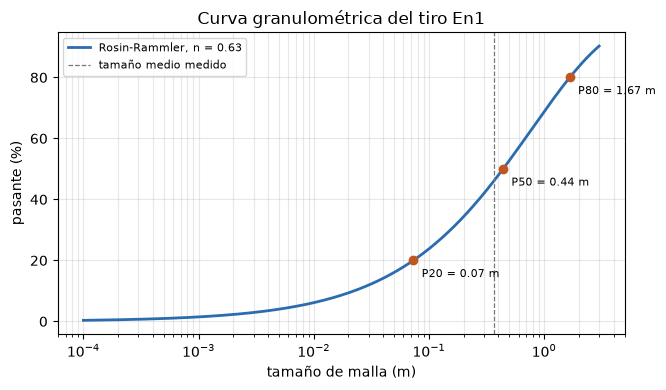

In [4]:
# Construir la curva de Rosin-Rammler del tiro y marcar los tamaños que lee un chancador
curve = bf.rosin_rammler(x50, n_engine)
marks = {fraction: curve.percentile_m(fraction) for fraction in (0.2, 0.5, 0.8)}
show_table(["pasante", "tamaño (m)"], [(f"P{int(f * 100)}", f"{m:.4f}") for f, m in marks.items()])
print(f"tamaño característico, pasa 63.2 %: {curve.detail['characteristic_size_m']:.4f} m")
print(f"fracción que pasa el tamaño medio medido ({blast.x50_m} m): {curve.passing_at(blast.x50_m):.3f}")

fig, ax = plt.subplots(figsize=(6.8, 4))
ax.plot(curve.sizes_m, [100 * p for p in curve.passing], color="#2b6cb0", lw=2,
        label=f"Rosin-Rammler, n = {n_engine:.2f}")
for fraction, size in marks.items():
    ax.plot([size], [100 * fraction], "o", color="#c05621")
    ax.annotate(f"P{int(fraction * 100)} = {size:.2f} m", (size, 100 * fraction),
                xytext=(6, -12), textcoords="offset points", fontsize=8)
ax.axvline(blast.x50_m, color="#777", lw=0.9, ls="--", label="tamaño medio medido")
ax.set_xscale("log")
ax.set_xlabel("tamaño de malla (m)")
ax.set_ylabel("pasante (%)")
ax.set_title(f"Curva granulométrica del tiro {blast_id}")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()

La curva es una S suave en el eje logarítmico, y las tres marcas leen lo que especificaría un chancador: 20 por ciento de la masa es más fina que 0,0732 m, la mitad es más fina que 0,4399 m y 80 por ciento es más fina que 1,6679 m. El tamaño característico, por el que pasa 63,2 por ciento, es 0,7855 m, y el tamaño medio medido de 0,37 m deja solo 0,463 de la masa por debajo en esta curva, de modo que el modelo es algo más grueso que la medición. La figura no muestra una distribución de tamaños medida, porque no existe para este tiro: solo se midió el tamaño medio, y toda la forma proviene de `n` = 0,63. Lo que sigue es la pregunta de cómo cambiaría esa forma con `n`.

### Paso 4: mover el índice con el tamaño medio fijo

Para aislar el índice, la celda construye seis curvas con el mismo tamaño medio y `n` de 0,5 a 3, un rango que cubre los valores que produce el corpus. La tabla da el P20, el P50, el P80 y su razón, y la figura superpone las curvas con el tamaño medio marcado.

n,P20 (m),P50 (m),P80 (m),P80 / P20
0.5,0.0456,0.4399,2.3717,52.0
0.75,0.0970,0.4399,1.3526,13.9
1.0,0.1416,0.4398,1.0214,7.2
1.5,0.2066,0.4398,0.7715,3.7
2.0,0.2495,0.4398,0.6703,2.7
3.0,0.3013,0.4398,0.5826,1.9


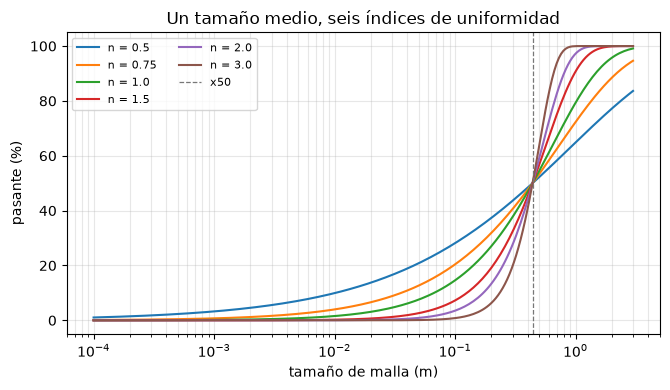

In [5]:
# Mismo tamaño medio, seis índices de uniformidad: la curva y los tamaños que implica
indices = [0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
sweep = {n: bf.rosin_rammler(x50, n) for n in indices}
rows = []
for n, shape in sweep.items():
    p20, p80 = shape.percentile_m(0.2), shape.percentile_m(0.8)
    rows.append((n, f"{p20:.4f}", f"{shape.percentile_m(0.5):.4f}", f"{p80:.4f}", f"{p80 / p20:.1f}"))
show_table(["n", "P20 (m)", "P50 (m)", "P80 (m)", "P80 / P20"], rows)

fig, ax = plt.subplots(figsize=(6.8, 4))
for n, shape in sweep.items():
    ax.plot(shape.sizes_m, [100 * p for p in shape.passing], label=f"n = {n}")
ax.axvline(x50, color="#777", lw=0.9, ls="--", label="x50")
ax.set_xscale("log")
ax.set_xlabel("tamaño de malla (m)")
ax.set_ylabel("pasante (%)")
ax.set_title("Un tamaño medio, seis índices de uniformidad")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()

Las seis curvas se cruzan en el tamaño medio y se abren a ambos lados, que es todo el efecto del índice. Con `n` = 0,5 el P20 es 0,0456 m y el P80 es 2,3717 m, una razón de 52,0; con `n` = 3 el P20 sube a 0,3013 m y el P80 baja a 0,5826 m, una razón de 1,9. El P50 queda en 0,4399 m o 0,4398 m en todas las filas, de modo que un cambio de `n` redistribuye masa entre los finos y el sobretamaño sin tocar la mediana. La figura no dice qué `n` tiene un tiro dado, ni cuál curva está más cerca de la verdad; para eso hace falta el patrón, que aporta el paso 5.

### Paso 5: el índice en el corpus

El índice depende solo del patrón, así que puede calcularse para todo tiro con geometría (los otros seis no publican diámetro de taladro, y el motor se niega a inventar uno). La celda reutiliza la función de factores del paso 2 en todos ellos, tabula el rango de cada factor y cuenta los tiros dentro del rango usual de 0,7 a 2 que indican Amoako, Jha y Zhong.

In [6]:
# El índice de cada tiro con geometría, y lo que hace cada uno de sus factores en el corpus
with_geometry = [b for b in train if bf.has_absolute_geometry(b)]
patterns = [bf.reconstruct_pattern(b) for b in with_geometry]
n_all = np.array([bf.cunningham_uniformity_index(p) for p in patterns])
per_blast = [index_factors(p) for p in patterns]
rows = []
for name in per_blast[0]:
    values = np.array([f[name] for f in per_blast])
    rows.append((name, f"{values.min():.3f}", f"{np.median(values):.3f}", f"{values.max():.3f}"))
rows.append(("n (el producto)", f"{n_all.min():.3f}", f"{np.median(n_all):.3f}", f"{n_all.max():.3f}"))
show_table(["factor", "mínimo", "mediana", "máximo"], rows)
usual = int(((n_all >= 0.7) & (n_all <= 2)).sum())
print(f"tiros con geometría: {len(n_all)} | dentro del rango usual 0.7 a 2: {usual}")

factor,mínimo,mediana,máximo
2.2 - 14 B/d,1.647,1.818,1.948
sqrt((1 + S/B) / 2),1.000,1.049,1.173
1 - W/B,1.000,1.000,1.000
"(|BCL - CCL| / L + 0.1)^0.1, una columna",0.794,0.794,0.794
L / H,0.120,0.632,0.900
n (el producto),0.184,0.950,1.362


tiros con geometría: 91 | dentro del rango usual 0.7 a 2: 62


En los 91 tiros el índice va de 0,184 a 1,362 con una mediana de 0,950, y 62 de ellos caen dentro del rango usual de 0,7 a 2, de modo que el resto queda por debajo y ninguno llega a la mitad superior de ese rango. La tabla explica por qué: el factor de bordo sobre diámetro solo se mueve entre 1,647 y 1,948, y el factor de espaciamiento entre 1,000 y 1,173, mientras que `L / H` va de 0,120 a 0,900. El índice de este corpus queda entonces fijado casi por completo por cuánto del banco está cargado, y no por la razón bordo sobre diámetro que la ecuación parece destacar. La tabla no muestra si el corpus es típico de otras minas; el rango usual proviene de la literatura y no de estos datos.

### Paso 6: la cola en el corpus

Por último, cada tiro recibe su propia curva desde su propio tamaño medio e índice, y se grafica la razón entre su P80 y su tamaño medio contra el índice. Si la forma cerrada de la sección de método es correcta, los puntos caen sobre una sola línea sea cual sea el tamaño medio, porque el tamaño medio se cancela. El panel izquierdo muestra cómo se distribuyen los propios índices frente al rango usual.

tiros cuyo P80 de forma cerrada queda más allá de la grilla de 3 m: 16 de 91
mayor diferencia entre el motor y la forma cerrada en los demás: 3.5e-04
P80 / tamaño medio, los demás: mín 1.86 | mediana 2.37 | máx 5.73


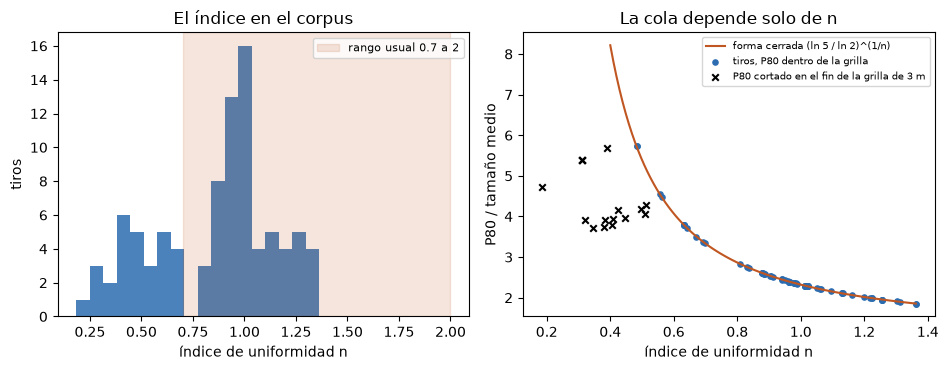

In [7]:
# El P80 de cada tiro frente a su tamaño medio, desde su propia curva, junto a la distribución del índice
x50_all = np.array([bf.Kuznetsov().predict_one(b).x50_m for b in with_geometry])
p80_ratio = np.array([bf.rosin_rammler(x, n).percentile_m(0.8) / x for x, n in zip(x50_all, n_all)])
closed_form = (np.log(5) / np.log(2)) ** (1 / n_all)
# Una curva que no llega a 80 por ciento en la grilla tiene su P80 leído en el último tamaño de la grilla
beyond_grid = closed_form * x50_all > bf.sieve_grid()[-1]
gap = np.abs(p80_ratio - closed_form)[~beyond_grid].max()
print(f"tiros cuyo P80 de forma cerrada queda más allá de la grilla de 3 m: {int(beyond_grid.sum())} de {len(n_all)}")
print(f"mayor diferencia entre el motor y la forma cerrada en los demás: {gap:.1e}")
inside = p80_ratio[~beyond_grid]
print(f"P80 / tamaño medio, los demás: mín {inside.min():.2f}",
      f"| mediana {np.median(inside):.2f} | máx {inside.max():.2f}")

fig, (left, right) = plt.subplots(1, 2, figsize=(9.6, 3.8))
left.hist(n_all, bins=18, color="#2b6cb0", alpha=0.85)
left.axvspan(0.7, 2.0, color="#c05621", alpha=0.15, label="rango usual 0.7 a 2")
left.set_xlabel("índice de uniformidad n")
left.set_ylabel("tiros")
left.set_title("El índice en el corpus")
left.legend(fontsize=8)
n_line = np.linspace(0.4, n_all.max(), 100)
right.plot(n_line, (np.log(5) / np.log(2)) ** (1 / n_line), color="#c05621", lw=1.5,
           label="forma cerrada (ln 5 / ln 2)^(1/n)")
right.scatter(n_all[~beyond_grid], inside, s=14, color="#2b6cb0",
              label="tiros, P80 dentro de la grilla")
right.scatter(n_all[beyond_grid], p80_ratio[beyond_grid], s=22, marker="x", color="black",
              label="P80 cortado en el fin de la grilla de 3 m")
right.set_xlabel("índice de uniformidad n")
right.set_ylabel("P80 / tamaño medio")
right.set_title("La cola depende solo de n")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

El panel izquierdo confirma la tabla: los índices se agrupan entre 0,7 y 1,4, con un segundo grupo de valores menores bajo 0,7. En el panel derecho, 75 tiros quedan sobre la línea de forma cerrada con una diferencia de 3.5e-04 y la razón entre el P80 y el tamaño medio cae de 5,73 en el índice más bajo a 1,86 cerca del más alto, con una mediana de 2,37; el tamaño medio es irrelevante para esa razón. Las 16 cruces son tiros cuyo P80 de forma cerrada queda más allá de la grilla de 3 m: el motor lee ese P80 en el último tamaño de la grilla, así que bajo un índice de cerca de 0,5 el extremo grueso de la curva queda cortado, no medido. La figura no muestra si algún tiro realmente se fragmenta con colas tan gruesas; el notebook siguiente introduce el bloque in situ que las acota.

## Resultados

**Respuesta:** el índice de uniformidad fija el ancho de la curva granulométrica y deja su mediana donde la pone el tamaño medio. Con el tamaño medio fijo en 0,4399 m, subir `n` de 0,5 a 3 eleva el P20 de 0,0456 m a 0,3013 m y baja el P80 de 2,3717 m a 0,5826 m. Para el tiro de Enusa `n` vale 0,6321, lo que da un P20 de 0,0732 m y un P80 de 1,6679 m. En los 91 tiros con geometría el índice va de 0,184 a 1,362, 62 de ellos dentro del rango usual de 0,7 a 2, y lo gobierna sobre todo la fracción cargada del banco (`L / H`, de 0,120 a 0,900). En los 75 tiros cuyo P80 queda dentro de la grilla de mallas, el P80 es exactamente el tamaño medio por una función de `n`, con una razón mediana de 2,37.

**Lo que esto no muestra.** El corpus no contiene ninguna distribución de tamaños medida, de modo que ninguna de estas curvas está validada: son la forma del modelo clásico, y que un `n` mayor sea una distribución más estrecha es una propiedad de la ecuación, no un hallazgo sobre la roca. El índice además toma la desviación de perforación como cero en todo tiro, lo que elimina uno de sus propios factores. Por último, el motor lee un P80 mayor que 3 m como 3 m, así que los 16 tiros de menor índice tienen un extremo grueso que este notebook no puede informar.

## Resumen

- El índice `n` es el ancho de la curva de Rosin-Rammler: con un tamaño medio fijo cambia finos por sobretamaño y deja quieto el P50.
- El índice de Cunningham es un producto de cinco factores con unidades mixtas; en este corpus lo gobierna la fracción cargada `L / H`.
- Todo P80 es el tamaño medio por una función de `n` solamente, hasta que la curva sale de la grilla de mallas de 3 m.
- Siguiente: el notebook 02 compara esta curva con las formas Swebrec y de zona de trituración y la acota en el bloque in situ.

## Referencias

- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (Ecs. 5 y 7)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/